# Fashion-MNIST Image Classification using a Feedforward Neural Network

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd # Needed for CSV loading


# # 1. Read the CSV files (each row has 785 values: 1 label + 784 pixels)
train_df = pd.read_csv('fashion-mnist_train.csv')
test_df = pd.read_csv('fashion-mnist_test.csv')


#
# # 2. Separate labels and normalized pixel values
y_train = train_df['label'].values
y_test = test_df['label'].values
#
# # Drop the label column to extract only pixel data and scale to [0, 1]
X_train_flat = train_df.drop(columns=['label']).values / 255.0
X_test_flat = test_df.drop(columns=['label']).values / 255.0
#
# # 3. Convert flat 1D rows (784 features) back into 2D images (28x28)
# # so the rest of the code works seamlessly without architectural changes:
X_train = X_train_flat.reshape(-1, 28, 28)
X_test = X_test_flat.reshape(-1, 28, 28)

# Alternative: Load Fashion-MNIST directly using Keras
# (X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()
# X_train = X_train / 255.0
# X_test = X_test / 255.0
# =====================================================================


# Class names for reference
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print(f"Training data shape: {X_train.shape}")
print(f"Test data shape: {X_test.shape}")

Training data shape: (60000, 28, 28)
Test data shape: (10000, 28, 28)


In [2]:
# 2. Build and Train the Feedforward Neural Network
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),  # Flatten 2D images to 1D vector
    keras.layers.Dense(128, activation='relu'),   # Hidden layer 1
    keras.layers.Dense(64, activation='relu'),    # Hidden layer 2
    keras.layers.Dense(10, activation='softmax')   # Output layer
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(X_train, y_train, epochs=10, validation_split=0.1, batch_size=64)

C:\Users\asus\.conda\envs\base_rebuild\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8169 - loss: 0.5218 - val_accuracy: 0.8477 - val_loss: 0.4255
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8607 - loss: 0.3875 - val_accuracy: 0.8650 - val_loss: 0.3805
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8722 - loss: 0.3481 - val_accuracy: 0.8660 - val_loss: 0.3753
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8798 - loss: 0.3262 - val_accuracy: 0.8783 - val_loss: 0.3420
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8866 - loss: 0.3081 - val_accuracy: 0.8788 - val_loss: 0.3425
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8937 - loss: 0.2885 - val_accuracy: 0.8785 - val_loss: 0.3385
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8976 - loss: 0.2786 - val_accuracy: 0.8853 - val_loss: 0.3252
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9016 - loss: 0.2653 - val_accuracy: 0.

In [3]:
# 3. Evaluate the Model on Test Data
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nTest Accuracy: {test_acc:.4f}")

313/313 - 1s - 3ms/step - accuracy: 0.8864 - loss: 0.3248

Test Accuracy: 0.8864


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step


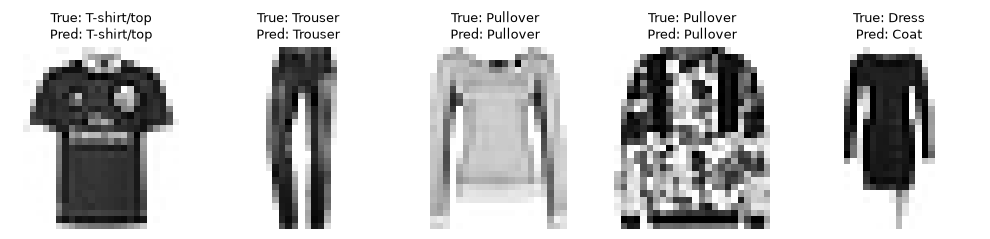

In [4]:
# 4. Predict and Display 5 Test Images with Labels
predictions = model.predict(X_test[:5])
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(10, 3))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(X_test[i], cmap='binary')
    plt.axis('off')
    actual_label = class_names[y_test[i]]
    pred_label = class_names[predicted_labels[i]]
    plt.title(f"True: {actual_label}\nPred: {pred_label}", fontsize=9)
plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


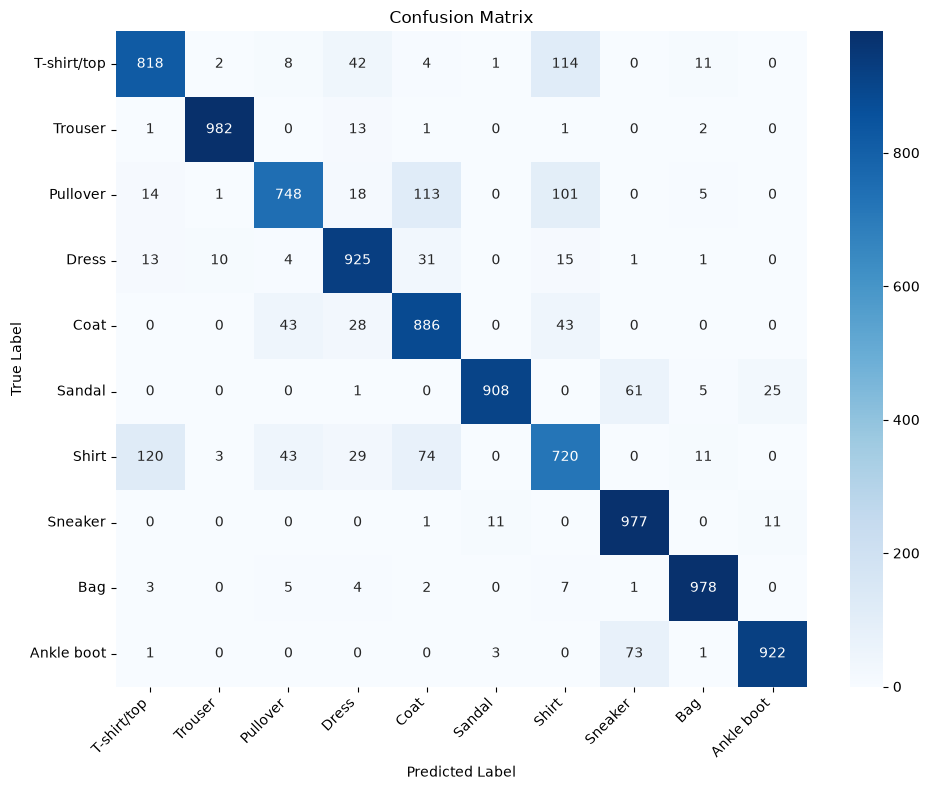

In [5]:
# 5. Generate and Plot the Confusion Matrix
all_predictions = model.predict(X_test)
y_pred = np.argmax(all_predictions, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [6]:
# Quick analysis: what does the FNN get wrong?
from collections import Counter

# Get misclassified samples
misclassified = np.where(y_pred != y_test)[0]
print(f"Total misclassified: {len(misclassified)} / {len(y_test)} "
      f"({100*len(misclassified)/len(y_test):.2f}%)")

# Count the top (true → predicted) confusion pairs
confusion_pairs = Counter(
    (class_names[y_test[i]], class_names[y_pred[i]])
    for i in misclassified
)

print("\nTop 5 most common mistakes:")
for (true_label, pred_label), count in confusion_pairs.most_common(5):
    print(f"  {true_label:>12s}  →  {pred_label:<12s}  :  {count} times")

Total misclassified: 1136 / 10000 (11.36%)

Top 5 most common mistakes:
         Shirt  →  T-shirt/top   :  120 times
   T-shirt/top  →  Shirt         :  114 times
      Pullover  →  Coat          :  113 times
      Pullover  →  Shirt         :  101 times
         Shirt  →  Coat          :  74 times
